TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 

Haz clic izquierdo sobre la moneda de 1 Euro en la ventana
Calibración completada: 0.1236 mm/píxel (Radio ref: 94.0 px)


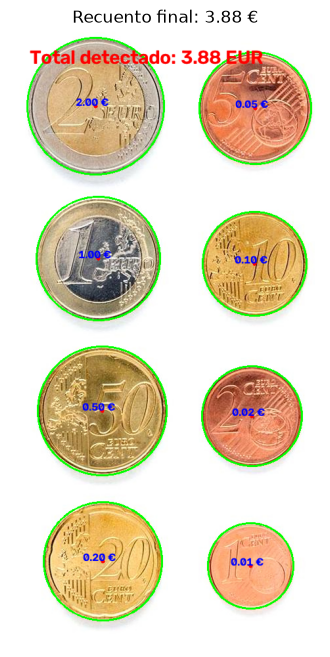

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Tabla de diámetros de cada moneda en milímetros
DIAMETROS_MONEDAS = {
    "2.00 €": 25.75,
    "0.50 €": 24.35, 
    "1.00 €": 23.25,
    "0.20 €": 22.25,
    "0.05 €": 21.25,
    "0.10 €": 19.75,
    "0.02 €": 18.75,
    "0.01 €": 16.25
}

VALORES_NUMERICOS = {
    "2.00 €": 2.00, "0.50 €": 0.50, "1.00 €": 1.00, "0.20 €": 0.20,
    "0.05 €": 0.05, "0.10 €": 0.10, "0.02 €": 0.02, "0.01 €": 0.01
}

# Cargar imagen
img = cv2.imread('Monedas.jpg')
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
suavizada = cv2.medianBlur(gris, 7)

# Al ser fondo blanco se invierte para tener las monedas en blanco
_, th = cv2.threshold(suavizada, 200, 255, cv2.THRESH_BINARY_INV)

# Localizar contornos exteriores
contornos, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

monedas = []
for c in contornos:
    if cv2.contourArea(c) > 500:  # Filtro mínimo de área
        (cx, cy), radio = cv2.minEnclosingCircle(c)
        monedas.append({'centro': (int(cx), int(cy)), 'radio_px': radio})
        
# Selección interactiva de la moneda de referencia (1 Euro = 23.25 mm)
click_pos = None

def click_callback(event, x, y, flags, param):
    global click_pos
    if event == cv2.EVENT_LBUTTONDOWN:
        click_pos = (x, y)

cv2.namedWindow('Calibracion: Haz clic en la moneda de 1 Euro')
cv2.setMouseCallback('Calibracion: Haz clic en la moneda de 1 Euro', click_callback)

img_calib = img.copy()
for m in monedas:
    cv2.circle(img_calib, m['centro'], int(m['radio_px']), (0, 255, 0), 2)

print("Haz clic izquierdo sobre la moneda de 1 Euro en la ventana")
while click_pos is None:
    cv2.imshow('Calibracion: Haz clic en la moneda de 1 Euro', img_calib)
    if cv2.waitKey(20) != -1:
        break
cv2.destroyAllWindows()

# Calcular escala píxeles/mm a partir de la moneda seleccionada
if click_pos is not None:
    # Buscar la moneda cuyo centro esté más próximo al punto de clic
    distancias = [np.hypot(m['centro'][0] - click_pos[0], m['centro'][1] - click_pos[1]) for m in monedas]
    idx_ref = int(np.argmin(distancias))
    radio_ref_px = monedas[idx_ref]['radio_px']
    
    mm_por_pixel = 23.25 / (2 * radio_ref_px)
    print(f"Calibración completada: {mm_por_pixel:.4f} mm/píxel (Radio ref: {radio_ref_px:.1f} px)")

    # Clasificar todas las monedas y sumar el dinero total
    total_dinero = 0.0
    img_resultado = img.copy()

    for m in monedas:
        diametro_mm = (2 * m['radio_px']) * mm_por_pixel
        
        # Encontrar la moneda del catálogo con diámetro más cercano
        nombre_moneda = min(DIAMETROS_MONEDAS.keys(), key=lambda k: abs(DIAMETROS_MONEDAS[k] - diametro_mm))
        valor = VALORES_NUMERICOS[nombre_moneda]
        total_dinero += valor

        # Marcar sobre la imagen
        cx, cy = m['centro']
        cv2.circle(img_resultado, (cx, cy), int(m['radio_px']), (0, 255, 0), 2)
        cv2.circle(img_resultado, (cx, cy), 3, (0, 0, 255), -1)
        cv2.putText(img_resultado, f"{nombre_moneda}", (cx - 30, cy),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 0, 0), 2)

    cv2.putText(img_resultado, f"Total detectado: {total_dinero:.2f} EUR", (30, 50),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 3)

    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
    plt.title(f"Recuento final: {total_dinero:.2f} €")
    plt.axis('off')
    plt.show()

In [ ]:
import cv2
import numpy as np

#Tablas de referencia de diámetros y valores de monedas
DIAMETROS_MONEDAS = {
    "2.00 €": 25.75, "0.50 €": 24.35, "1.00 €": 23.25, "0.20 €": 22.25,
    "0.05 €": 21.25, "0.10 €": 19.75, "0.02 €": 18.75, "0.01 €": 16.25
}

VALORES_NUMERICOS = {
    "2.00 €": 2.00, "0.50 €": 0.50, "1.00 €": 1.00, "0.20 €": 0.20,
    "0.05 €": 0.05, "0.10 €": 0.10, "0.02 €": 0.02, "0.01 €": 0.01
}

# Referencia para calibrar
MONEDA_REF = "1.00 €" 

vid = cv2.VideoCapture(0)
mm_por_pixel = None
click_coord = None

# Función para capturar clics del ratón 
def raton_click(event, x, y, flags, param):
    global click_coord
    if event == cv2.EVENT_LBUTTONDOWN:
        click_coord = (x, y)

cv2.namedWindow('Demostrador Monedas en Vivo')
cv2.setMouseCallback('Demostrador Monedas en Vivo', raton_click)
font = cv2.FONT_HERSHEY_SIMPLEX

# Lista de monedas estables detectadas 
monedas_estables = []

while True:
    ret, frame = vid.read()
    if not ret:
        break

    # Convertir a gris y suavizar 
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gris_blur = cv2.GaussianBlur(gris, (9, 9), 2.0)

    # Detección de círculos usando HoughCircles
    circulos = cv2.HoughCircles(
        gris_blur,
        cv2.HOUGH_GRADIENT,
        dp=1.1,
        minDist=60,
        param1=100,
        param2=48,
        minRadius=30,
        maxRadius=110
    )

    monedas_detectadas = []
    
    # Descartar círculos fuera del área de la imagen o sobre fondo blanco 
    if circulos is not None:
        circulos = np.round(circulos[0, :]).astype("int")
        alto_f, ancho_f = frame.shape[:2]

        for (x, y, r) in circulos:
            # Validar que el círculo esté completamente dentro de la imagen
            if x - r >= 0 and x + r < ancho_f and y - r >= 0 and y + r < alto_f:
                mascara = np.zeros(gris.shape, dtype=np.uint8)
                cv2.circle(mascara, (x, y), r, 255, -1)
                # Descarta zonas de folio blanco
                if cv2.mean(gris, mask=mascara)[0] < 210:
                    monedas_detectadas.append((x, y, r))

    # Asociar detecciones actuales con monedas previas
    nuevas_estables = []
    for (x, y, r) in monedas_detectadas:
        encontrada = False
        for m in monedas_estables:
            cx_ant, cy_ant = m['centro']
            # Si el centro está a menos de 20 píxeles, es la misma moneda en la mesa
            if np.hypot(x - cx_ant, y - cy_ant) < 20:
                m['centro'] = (x, y)
                m['radios'].append(r)
                # Búfer de los últimos 25 fotogramas
                if len(m['radios']) > 25:
                    m['radios'].pop(0)
                nuevas_estables.append(m)
                encontrada = True
                break
       
        # Si es una moneda nueva recién colocada
        if not encontrada:
            nuevas_estables.append({'centro': (x, y), 'radios': [r]})

    monedas_estables = nuevas_estables

    # Calibración interactiva
    if click_coord is not None and len(monedas_estables) > 0:
        # Buscar la moneda más cercana al clic para calibrar
        distancias = [np.hypot(m['centro'][0] - click_coord[0], m['centro'][1] - click_coord[1]) for m in monedas_estables]
        idx = int(np.argmin(distancias))
        radio_estable = float(np.median(monedas_estables[idx]['radios']))
        # Calcular la escala mm/píxel usando la moneda de referencia
        diametro_ref_mm = DIAMETROS_MONEDAS[MONEDA_REF]
        mm_por_pixel = diametro_ref_mm / (2 * radio_estable)
        print(f"Calibrado con {MONEDA_REF}: {mm_por_pixel:.4f} mm/px")
        click_coord = None

    total_dinero = 0.0

    # Dibujar y clasificar monedas estables
    for m in monedas_estables:
        cx, cy = m['centro']
        # La mediana elimina picos y oscilaciones de ruido
        r_mediano = float(np.median(m['radios']))
        r_int = int(round(r_mediano))

        # Clasificación de la moneda según el diámetro
        if mm_por_pixel is not None:
            diametro_mm = (2 * r_mediano) * mm_por_pixel
            clase = min(DIAMETROS_MONEDAS.keys(), key=lambda k: abs(DIAMETROS_MONEDAS[k] - diametro_mm))
           
            # Validar que la diferencia de diámetro sea razonable
            if abs(DIAMETROS_MONEDAS[clase] - diametro_mm) < 2.2:
                total_dinero += VALORES_NUMERICOS[clase]
                cv2.circle(frame, (cx, cy), r_int, (0, 255, 0), 2)
                cv2.putText(frame, clase, (cx - 25, cy), font, 0.55, (255, 0, 0), 2)
            else:
                cv2.circle(frame, (cx, cy), r_int, (0, 165, 255), 1)
        else:
            cv2.circle(frame, (cx, cy), r_int, (0, 255, 255), 2)

    # Interfaz en pantalla
    if mm_por_pixel is None:
        cv2.putText(frame, f"Haz clic sobre la moneda de {MONEDA_REF} para calibrar", (20, 35),
                    font, 0.65, (0, 0, 255), 2)
    else:
        cv2.putText(frame, f"Total: {total_dinero:.2f} EUR", (20, 40),
                    font, 1.0, (0, 255, 0), 2)
        cv2.putText(frame, f"Escala: {mm_por_pixel:.3f} mm/px", (20, 70),
                    font, 0.5, (200, 200, 200), 1)


    cv2.imshow('Demostrador Monedas en Vivo', frame)
    if cv2.waitKey(1) == 27:
        break

vid.release()
cv2.destroyAllWindows()



Calibrado con 1.00 €: 0.1292 mm/px


TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo